# BDA700 - Project Milestone 2
## Group 3

**This notebook is designed to run in Google Colab.** Upload it via **File → Upload notebook** at [colab.research.google.com](https://colab.research.google.com).


In Milestone 1 we explored the **UCI Heart Disease (Cleveland) cohort** (303 patients) and found what we called
**"The Flat-Line Trap"**: in patients *without* heart disease, maximum exercise heart rate (`thalach`) declines
steadily with age, while patients *with* heart disease start from a much lower peak and stay flat.

The gap is largest in **younger** patients, which makes a low peak heart rate in a young patient an early warning sign.

### Learning objectives

- Build a complete classical-ML Streamlit apps — classification —  with heart disease dataset, EDA, preprocessing, model training/evaluation, and live prediction UI.


## 1. Environment Setup

In [158]:
%pip install --quiet streamlit

import sys, warnings
import joblib
import seaborn as sns
import pandas as pd
import numpy as np
import streamlit as st
import sklearn
import matplotlib.pyplot as plt
import matplotlib

warnings.filterwarnings('ignore', category=FutureWarning)
print("Python version:", sys.version)
print("numpy version: ", np.__version__)
print("pandas version:", pd.__version__)
print("seaborn version:", sns.__version__)
print("Joblib version:", joblib.__version__)
print("Streamlit version:", st.__version__)

Python version: 3.13.18 (main, Oct 26 2026, 15:28:15) [GCC 13.3.0]
numpy version:  2.4.6
pandas version: 2.2.3
seaborn version: 0.13.2
Joblib version: 1.6.0
Streamlit version: 1.41.1


## 2. Loading the data

In [159]:
url = "https://archive.ics.uci.edu/ml/machine-learning-databases/heart-disease/processed.cleveland.data"
cols = ["age", "sex", "cp", "trestbps", "chol", "fbs", "restecg",
        "thalach", "exang", "oldpeak", "slope", "ca", "thal", "num"]

df = pd.read_csv(url, header=None, names=cols, na_values="?")
df.to_csv("heart_cleveland.csv", index=False)
print(df.shape)
df.head()

(303, 14)


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,num
0,63.0,1.0,1.0,145.0,233.0,1.0,2.0,150.0,0.0,2.3,3.0,0.0,6.0,0
1,67.0,1.0,4.0,160.0,286.0,0.0,2.0,108.0,1.0,1.5,2.0,3.0,3.0,2
2,67.0,1.0,4.0,120.0,229.0,0.0,2.0,129.0,1.0,2.6,2.0,2.0,7.0,1
3,37.0,1.0,3.0,130.0,250.0,0.0,0.0,187.0,0.0,3.5,3.0,0.0,3.0,0
4,41.0,0.0,2.0,130.0,204.0,0.0,2.0,172.0,0.0,1.4,1.0,0.0,3.0,0


## 3. Data Preparation

In [160]:
# info
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 303 entries, 0 to 302
Data columns (total 14 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       303 non-null    float64
 1   sex       303 non-null    float64
 2   cp        303 non-null    float64
 3   trestbps  303 non-null    float64
 4   chol      303 non-null    float64
 5   fbs       303 non-null    float64
 6   restecg   303 non-null    float64
 7   thalach   303 non-null    float64
 8   exang     303 non-null    float64
 9   oldpeak   303 non-null    float64
 10  slope     303 non-null    float64
 11  ca        299 non-null    float64
 12  thal      301 non-null    float64
 13  num       303 non-null    int64  
dtypes: float64(13), int64(1)
memory usage: 33.3 KB


In [161]:
# Checking missing values
df.isnull().sum()

,0
age,0
sex,0
cp,0
trestbps,0
chol,0
fbs,0
restecg,0
thalach,0
exang,0
oldpeak,0


We impute these missing values in the pipeline.

In [162]:
# Checking duplicates
print(df.duplicated().sum())

0


In [163]:
# Converting num to binary target variable
df['target'] = (df['num'] > 0).astype(int)
df['target'].value_counts()

,count
target,
0,164
1,139


In [180]:
# from the UCI dataset website - variables table
X = df.drop(columns=['num','target'])
y = df['target']

num_cols = ["age", "trestbps", "chol", "thalach", "oldpeak", "ca"]
cat_cols = ["restecg", "cp", "slope", "thal"]
bin_cols = ["sex", "exang", "fbs"]

print(f'X shape before transformation: {X.shape}')

X shape before transformation: (303, 13)


## 4. Preprocessing Pipeline with train/test split

In [181]:
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.model_selection import (train_test_split, StratifiedKFold, cross_validate,
                                     GridSearchCV, cross_val_predict)
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (precision_recall_curve, roc_auc_score, accuracy_score,
                             precision_score, recall_score, f1_score, confusion_matrix,
                             classification_report, roc_curve, ConfusionMatrixDisplay)

In [182]:
# preprocess
num_pipeline = Pipeline(steps=[
    ('imp', SimpleImputer(strategy='median')),
    ('sc', StandardScaler())
    ])

cat_pipeline = Pipeline(steps=[
    ('imp', SimpleImputer(strategy='most_frequent')),
    ('ohe', OneHotEncoder(handle_unknown='ignore'))
    ])

# one-hot encoding already binary var adds noise
bin_pipeline = Pipeline(steps=[
    ('imp', SimpleImputer(strategy='most_frequent'))
])

preprocess = ColumnTransformer(transformers=[
    ('num', num_pipeline, num_cols),
    ('cat', cat_pipeline, cat_cols),
    ('bin', bin_pipeline, bin_cols)
    ])

# splitting the dataset into train and test
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42)

print(f'X_train shape: {X_train.shape}')
print(f'X_test shape: {X_test.shape}')

X_train shape: (242, 13)
X_test shape: (61, 13)


## 5. Model Comparison: GridSearchCV with stratified 5-fold CV

In [183]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
metrics = ['accuracy', 'precision', 'recall', 'f1', 'roc_auc']

models = {
    "LogReg": (LogisticRegression(max_iter=1000, solver="liblinear"),
               {"clf__C": [0.01, 0.1, 0.3, 1, 3, 10], "clf__penalty": ["l1", "l2"]}),
    "RandomForest": (RandomForestClassifier(n_estimators=300, random_state=42),
               {"clf__max_depth": [3, 5, 8, None], "clf__min_samples_leaf": [1, 5, 10],
                "clf__max_features": ["sqrt", "log2"]}),
    "SVC": (SVC(probability=True, random_state=42),
               {"clf__C": [0.1, 1, 10], "clf__kernel": ["rbf", "linear"]}),
    "KNN": (KNeighborsClassifier(),
               {"clf__n_neighbors": [5, 9, 15, 21, 31], "clf__weights": ["uniform", "distance"]}),
}

rows, searches = [], {}
for name, (clf, grid) in models.items():
    pipe = Pipeline([("prep", preprocess), ("clf", clf)])
    gs = GridSearchCV(pipe, grid, cv=cv, scoring=metrics,
                      refit="roc_auc", n_jobs=-1)
    gs.fit(X_train, y_train) # fitting model
    i = gs.best_index_
    rows.append({"model": name,
                 **{m: gs.cv_results_[f"mean_test_{m}"][i] for m in metrics},
                 "roc_auc_std": gs.cv_results_["std_test_roc_auc"][i],
                 "best_params": gs.best_params_})
    searches[name] = gs

results = pd.DataFrame(rows).sort_values("roc_auc", ascending=False).round(3)
results.to_csv("cv_results.csv", index=False)
results

,model,accuracy,precision,recall,f1,roc_auc,roc_auc_std,best_params
0,LogReg,0.843,0.878,0.774,0.819,0.907,0.019,"{'clf__C': 1, 'clf__penalty': 'l2'}"
2,SVC,0.855,0.896,0.783,0.831,0.904,0.024,"{'clf__C': 0.1, 'clf__kernel': 'linear'}"
1,RandomForest,0.818,0.825,0.774,0.794,0.898,0.025,"{'clf__max_depth': 5, 'clf__max_features': 'sq..."
3,KNN,0.793,0.817,0.711,0.758,0.890,0.022,"{'clf__n_neighbors': 9, 'clf__weights': 'dista..."


In [184]:
best_name, best_params = results.loc[0, 'model'], searches["LogReg"].best_params_
best_model = searches['LogReg'].best_estimator_
print(f'Best model: {best_name}')
print(f'Best params: {best_params}')

Best model: LogReg
Best params: {'clf__C': 1, 'clf__penalty': 'l2'}


**Choice: Logistic Regression.**

It is tied for best, among the most stable across folds, and, most importantly
for a health app, **interpretable**: each coefficient says how a feature moves risk, which lets us check the model
against clinical knowledge and against our Milestone 1 finding. It is also the lightest model to deploy.

## 6. Choosing a decision threshold
`predict()` uses a 0.5 probability cut-off by default. For a **screening** tool, a missed at-risk patient
(false negative) is costlier than a false alarm, which leads to further tests. So we set a recall target of **≥ 85%** and pick the
highest threshold that reaches it.

To avoid leakage, the threshold is chosen from **out-of-fold predictions on the training set**, never from the test set.

In [185]:
# Shared plot style (same two colours as our Milestone 1 storytelling chart)
NORMAL_C, RISK_C, INK, MUTED = "#2a78d6", "#eb6834", "#0b0b0b", "#52514e"

Chosen threshold: 0.331  (out-of-fold recall 0.856, precision 0.742)


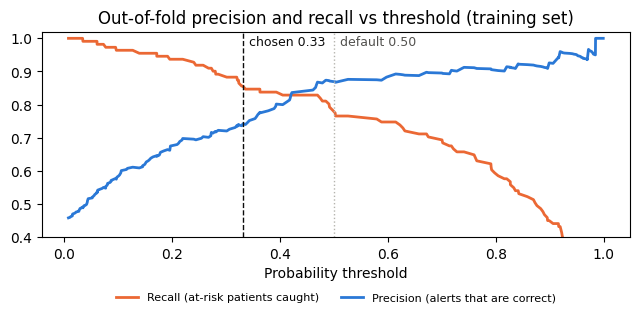

In [186]:
RECALL_TARGET = 0.85
oof = cross_val_predict(best_model, X_train, y_train, cv=cv, method="predict_proba")[:, 1]
prec, rec, thr = precision_recall_curve(y_train, oof)
ok = np.where(rec[:-1] >= RECALL_TARGET)[0]
threshold = float(thr[ok[-1]]) if len(ok) else 0.5
print(f"Chosen threshold: {threshold:.3f}  "
      f"(out-of-fold recall {rec[ok[-1]]:.3f}, precision {prec[ok[-1]]:.3f})")

fig, ax = plt.subplots(figsize=(6.5, 3.4))
ax.plot(thr, rec[:-1], color=RISK_C, lw=2, label="Recall (at-risk patients caught)")
ax.plot(thr, prec[:-1], color=NORMAL_C, lw=2, label="Precision (alerts that are correct)")
ax.axvline(threshold, color=INK, lw=1, ls="--")
ax.axvline(0.5, color="#b5b4ae", lw=1, ls=":")
ax.annotate(f"chosen {threshold:.2f}", (threshold, 1.02), xytext=(4, -10), textcoords="offset points",
            fontsize=9, color=INK)
ax.annotate("default 0.50", (0.5, 1.02), xytext=(4, -10), textcoords="offset points", fontsize=9, color=MUTED)
ax.set_xlabel("Probability threshold"); ax.set_ylim(0.4, 1.02)
ax.set_title("Out-of-fold precision and recall vs threshold (training set)")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.22), ncol=2, fontsize=8, frameon=False)
plt.tight_layout(); plt.show()

## 7. Final evaluation on the held-out test set

In [187]:
y_proba = best_model.predict_proba(X_test)[:, 1]
y_pred = (y_proba >= threshold).astype(int)
y_pred_05 = (y_proba >= 0.5).astype(int)

def summarise(y_hat):
    return {"accuracy": accuracy_score(y_test, y_hat), "precision": precision_score(y_test, y_hat),
            "recall": recall_score(y_test, y_hat), "f1": f1_score(y_test, y_hat)}

test_auc = roc_auc_score(y_test, y_proba)
comparison = pd.DataFrame({f"Screening threshold ({threshold:.2f})": summarise(y_pred),
                           "Default threshold (0.50)": summarise(y_pred_05)}).T
comparison["roc_auc"] = test_auc
comparison.round(3)

,accuracy,precision,recall,f1,roc_auc
Screening threshold (0.33),0.820,0.730,0.964,0.831,0.96
Default threshold (0.50),0.869,0.812,0.929,0.867,0.96


                    precision    recall  f1-score   support

            Normal       0.96      0.70      0.81        33
Heart Disease Risk       0.73      0.96      0.83        28

          accuracy                           0.82        61
         macro avg       0.84      0.83      0.82        61
      weighted avg       0.85      0.82      0.82        61



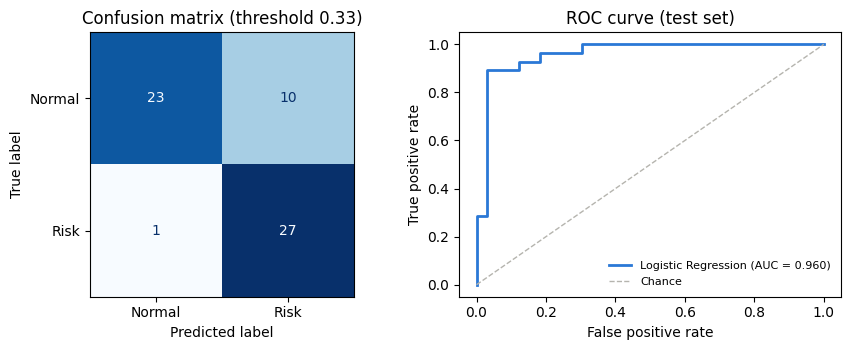

In [188]:
print(classification_report(y_test, y_pred, target_names=['Normal', 'Heart Disease Risk']))

fig, axes = plt.subplots(1, 2, figsize=(9, 3.6))
ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred, display_labels=["Normal", "Risk"], cmap="Blues", colorbar=False, ax=axes[0])
axes[0].set_title(f"Confusion matrix (threshold {threshold:.2f})"); axes[0].grid(False)

fpr, tpr, _ = roc_curve(y_test, y_proba)
axes[1].plot(fpr, tpr, color=NORMAL_C, lw=2, label=f"Logistic Regression (AUC = {test_auc:.3f})")
axes[1].plot([0, 1], [0, 1], color="#b5b4ae", lw=1, ls="--", label="Chance")
axes[1].set_xlabel("False positive rate"); axes[1].set_ylabel("True positive rate")
axes[1].set_title("ROC curve (test set)"); axes[1].legend(loc="lower right", fontsize=8, frameon=False)
plt.tight_layout(); plt.show()

- At the screening threshold the model catches **27 of 28** at-risk test patients (recall ≈ 0.96) at the cost of 8 false alarms (precision ≈ 0.73).
- At 0.50 it misses 2 and raises 6 false alarms. We accept the extra false alarms because the cost of a false alarm is a follow-up test, while a miss could mean untreated disease.
- Test ROC-AUC (≈ 0.96) is **higher than the cross-validated estimate (≈ 0.91)**. With only 61 test patients this is partly a favourable split. We treat **≈ 0.91 as the realistic expectation**.

## 8. Does this model agree with Milestone 1?

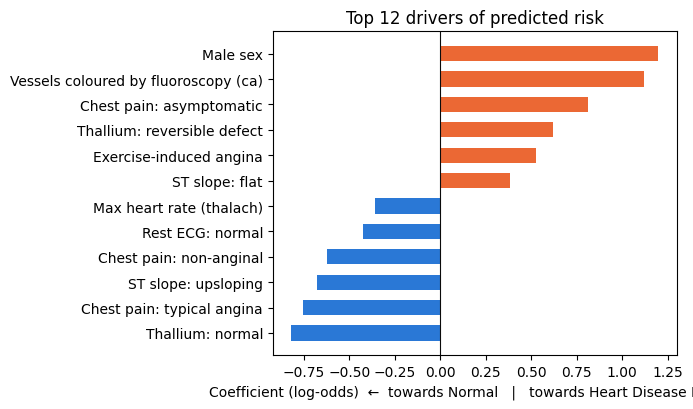

Max heart rate coefficient: -0.36  (negative = lower peak heart rate -> higher risk)


In [189]:
FEATURE_LABELS = {
    "num__age": "Age", "num__trestbps": "Resting blood pressure", "num__chol": "Cholesterol",
    "num__thalach": "Max heart rate (thalach)", "num__oldpeak": "ST depression (oldpeak)",
    "num__ca": "Vessels coloured by fluoroscopy (ca)",
    "bin__sex": "Male sex", "bin__fbs": "Fasting blood sugar > 120", "bin__exang": "Exercise-induced angina",
    "cat__cp_1.0": "Chest pain: typical angina", "cat__cp_2.0": "Chest pain: atypical angina",
    "cat__cp_3.0": "Chest pain: non-anginal", "cat__cp_4.0": "Chest pain: asymptomatic",
    "cat__restecg_0.0": "Rest ECG: normal", "cat__restecg_1.0": "Rest ECG: ST-T abnormality",
    "cat__restecg_2.0": "Rest ECG: LV hypertrophy",
    "cat__slope_1.0": "ST slope: upsloping", "cat__slope_2.0": "ST slope: flat",
    "cat__slope_3.0": "ST slope: downsloping",
    "cat__thal_3.0": "Thallium: normal", "cat__thal_6.0": "Thallium: fixed defect",
    "cat__thal_7.0": "Thallium: reversible defect",
}
names = best_model.named_steps["prep"].get_feature_names_out()
coefs = pd.Series(best_model.named_steps["clf"].coef_[0], index=names).rename(index=FEATURE_LABELS)
top = coefs.reindex(coefs.abs().sort_values(ascending=False).index).head(12).sort_values()

fig, ax = plt.subplots(figsize=(7, 4.2))
ax.barh(top.index, top.values, color=[RISK_C if v > 0 else NORMAL_C for v in top.values], height=0.6)
ax.axvline(0, color=INK, lw=0.8)
ax.set_xlabel("Coefficient (log-odds)  ←  towards Normal   |   towards Heart Disease Risk  →")
ax.set_title("Top 12 drivers of predicted risk")
ax.grid(axis="y", visible=False)
plt.tight_layout(); plt.show()

print(f"Max heart rate coefficient: {coefs['Max heart rate (thalach)']:+.2f}  "
      f"(negative = lower peak heart rate -> higher risk)")

**Agreement with Milestone 1.**
- **Max heart rate has a negative coefficient**: a lower peak heart rate raises predicted risk, which is exactly the "flat-line" side of our Milestone 1 chart.
- Age adds almost nothing once heart rate is in the model (coefficient ≈ −0.1).
- The strongest risk drivers are male sex, more vessels coloured by fluoroscopy (`ca`), **asymptomatic chest pain**, a reversible thallium defect and exercise-induced angina. "Asymptomatic" counter-intuitively signals the *highest* risk in this cohort, so the app explains this to users.

## Model Serialization

In [190]:
joblib.dump(best_model, "classification_model.joblib")

reqs = f"""streamlit>=1.41
scikit-learn=={sklearn.__version__}
numpy=={np.__version__}
pandas=={pd.__version__}
joblib=={joblib.__version__}
matplotlib=={matplotlib.__version__}
"""
with open("requirements.txt", "w") as f:
    f.write(reqs)

print("\nrequirements.txt:\n" + reqs)



requirements.txt:
streamlit>=1.41
scikit-learn==1.9.0
numpy==2.4.6
pandas==2.2.3
joblib==1.6.0
matplotlib==3.10.0



## Streamlit App Architecture

In [ ]:
%%writefile classification_app.py

# imports
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import streamlit as st

# page setup
st.set_page_config(page_title="Heart Disease Risk Predictor", page_icon="🫀")


# load the model and the data (once, then cached)
@st.cache_resource
def load_model():
    return joblib.load("classification_model.joblib")


@st.cache_data
def load_data():
    df = pd.read_csv("heart_cleveland.csv")
    df["target"] = (df["num"] > 0).astype(int)
    return df


model = load_model()
data = load_data()

THRESHOLD = 0.33
FEATURES = ["age", "trestbps", "chol", "thalach", "oldpeak", "ca",
            "sex", "fbs", "exang", "cp", "restecg", "slope", "thal"]

# title
st.title("🫀 Heart Disease Risk Predictor")
st.write("Predicts the probability of heart disease from 13 clinical measurements, using a logistic "
         "regression model trained on the UCI Heart Disease (Cleveland) dataset. "
         "BDA700 Group 3: Vidhi Parmar & Sam Alavi.")
st.caption("Educational project, not a medical device.")

# inputs in the sidebar (users see words, the model gets numbers)
CP = {"Typical angina": 1, "Atypical angina": 2, "Non-anginal pain": 3, "Asymptomatic (no chest pain)": 4}
RESTECG = {"Normal": 0, "ST-T wave abnormality": 1, "Left ventricular hypertrophy": 2}
SLOPE = {"Upsloping": 1, "Flat": 2, "Downsloping": 3}
THAL = {"Normal": 3, "Fixed defect": 6, "Reversible defect": 7}
YES_NO = {"No": 0, "Yes": 1}

st.sidebar.header("Patient details")
age = st.sidebar.number_input("Age (years)", min_value=18, max_value=100, value=55)
sex = st.sidebar.radio("Sex", ["Female", "Male"])
cp = st.sidebar.selectbox("Chest pain type", list(CP))
trestbps = st.sidebar.number_input("Resting blood pressure (mm Hg)", 80, 220, 130)
chol = st.sidebar.number_input("Cholesterol (mg/dl)", 100, 600, 240)
fbs = st.sidebar.radio("Fasting blood sugar above 120 mg/dl?", list(YES_NO))
restecg = st.sidebar.selectbox("Resting ECG", list(RESTECG))
thalach = st.sidebar.number_input("Maximum heart rate during exercise (bpm)", 60, 220, 150)
exang = st.sidebar.radio("Chest pain during exercise?", list(YES_NO))
oldpeak = st.sidebar.number_input("ST depression during exercise (oldpeak)", 0.0, 6.5, 1.0, step=0.1)
slope = st.sidebar.selectbox("Slope of the ST segment", list(SLOPE))
ca = st.sidebar.selectbox("Major vessels coloured by fluoroscopy", [0, 1, 2, 3])
thal = st.sidebar.selectbox("Thallium stress test", list(THAL))

predict = st.sidebar.button("Predict risk", type="primary")

# prediction
if predict:
    patient = pd.DataFrame([{
        "age": age, "sex": 1 if sex == "Male" else 0, "cp": CP[cp], "trestbps": trestbps,
        "chol": chol, "fbs": YES_NO[fbs], "restecg": RESTECG[restecg], "thalach": thalach,
        "exang": YES_NO[exang], "oldpeak": oldpeak, "slope": SLOPE[slope], "ca": ca, "thal": THAL[thal],
    }])[FEATURES]

    prob = model.predict_proba(patient)[0, 1]

    st.subheader("Result")
    if prob >= THRESHOLD:
        st.error(f"⚠️ Heart Disease Risk: predicted probability {prob:.0%}")
    else:
        st.success(f"✅ Normal / Low Risk: predicted probability {prob:.0%}")
    st.progress(float(prob))
    st.caption(f"Patients at or above {THRESHOLD:.0%} are flagged. We use a low threshold on purpose: "
               "in screening, missing a sick patient is worse than a false alarm.")

    # milestone 1 chart with this patient on it
    st.subheader("Our Milestone 1 finding: the Flat-Line Trap")
    st.write("Without heart disease, maximum heart rate drops steadily with age. With heart disease it starts "
             "lower and stays flat. The star shows this patient.")

    fig, ax = plt.subplots(figsize=(7, 4))
    for target, color, label in [(0, "#2a78d6", "No heart disease"), (1, "#eb6834", "Heart disease")]:
        group = data[data["target"] == target]
        ax.scatter(group["age"], group["thalach"], color=color, alpha=0.3, s=15)
        m, b = np.polyfit(group["age"], group["thalach"], 1)
        ax.plot(group["age"], m * group["age"] + b, color=color, linewidth=2.5, label=label)
    ax.scatter(age, thalach, marker="*", s=300, color="black", label="This patient", zorder=3)
    ax.set_xlabel("Age (years)")
    ax.set_ylabel("Maximum heart rate (bpm)")
    ax.legend()
    st.pyplot(fig)

    healthy = data[data["target"] == 0]
    m, b = np.polyfit(healthy["age"], healthy["thalach"], 1)
    expected = m * age + b
    st.write(f"At age {age}, people without heart disease reach about **{expected:.0f} bpm** on average. "
             f"This patient reached **{thalach} bpm** ({thalach - expected:+.0f} bpm).")
else:
    st.info("👈 Enter the patient's details in the sidebar and press **Predict risk**.")

# model summary
st.divider()
st.subheader("About the model")
col1, col2, col3 = st.columns(3)
col1.metric("ROC-AUC (cross-validated)", "0.91")
col2.metric("Recall (test set)", "96%")
col3.metric("Precision (test set)", "73%")
st.write("We compared Logistic Regression, Random Forest, SVC and KNN with 5-fold cross-validation. "
         "All scored about the same, so we chose Logistic Regression because it is the easiest to interpret. "
         "Recall is the share of sick patients the model catches; precision is the share of flagged "
         "patients who are actually sick.")

Overwriting classification_app.py
